# NewsBot 2.0 · Notebook 01 – Data Exploration
**ITAI 2373 Final Project · Mourinho Hernanto**

**Goal:** load both corpora, validate data quality and understand what the system works with.

**Course modules:** 1 (NLP applications), 2 (preprocessing), 3 (features)

> Runs top-to-bottom in Google Colab (first cell installs everything). All logic lives in `src/` –
> this notebook demonstrates and evaluates it.

In [1]:
# ⚙️ Setup – works in Google Colab (clones the repo + installs) and locally
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content/ITAI2373-NewsBot-Final/ITAI2373-NewsBot-Final") if IN_COLAB else Path.cwd().resolve().parent
if IN_COLAB and not ROOT.exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/Haryapandhita/ITAI2373-NewsBot-Final.git",
                    "/content/ITAI2373-NewsBot-Final"], check=True)
sys.path.insert(0, str(ROOT))
from scripts.colab_setup import setup
ROOT = setup()

import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
# Transformer models (summarisation, translation, multilingual embeddings) are used when
# available (Colab: Runtime -> Change runtime type -> T4 GPU recommended); otherwise
# NewsBot falls back to classical methods automatically.
USE_TRANSFORMERS = os.environ.get("NEWSBOT_USE_TRANSFORMERS", "1") == "1"
print("Transformers enabled:", USE_TRANSFORMERS)

Project root: /home/claude/NewsBot-Final/ITAI2373-NewsBot-Final  |  Colab: False


Transformers enabled: True


## 1. Load the data
Two public datasets are downloaded on first use (not stored in the repo):
* **BBC News** – 2,225 English articles (2004–05) in 5 categories, **original casing and headlines**.
  The midterm used the lower-cased Kaggle copy, which broke NER; this version fixes that.
* **Webz.io free news** – 20 weekly snapshots, **6 languages, dated Dec 2023 – Nov 2026**, with category and sentiment labels.
  This is what makes topic/sentiment *evolution* and the *multilingual* module possible.

In [2]:
from src.data_processing.data_loader import load_all
data = load_all()
bbc, webz = data["bbc"], data["webz"]
print("BBC :", bbc.shape, "| Webz:", webz.shape)
bbc.head(3)

BBC : (2092, 6) | Webz: (13213, 12)


,doc_id,title,text,category,source,language
0,bbc_business_001,Ad sales boost Time Warner profit,"Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from ...",business,bbc,en
1,bbc_business_002,Dollar gains on Greenspan speech,The dollar has hit its highest level against the euro in almost three months after the Federal Reserve head said the...,business,bbc,en
2,bbc_business_003,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yukos are to ask the buyer of its former production unit to pay back a $90...,business,bbc,en


In [3]:
webz[["title", "language", "category", "published", "site", "webz_sentiment"]].sample(6, random_state=1)

,title,language,category,published,site,webz_sentiment
1932,Paris Baguette Opens First U.S. Drive-Through Store in Oklahoma,en,business,2026-11-13 05:13:00+00:00,sedaily.com,positive
4777,Nation vows to boost ties with Solomon Islands - Chinadaily.com.cn,en,politics,2024-07-11 23:15:28+00:00,chinadaily.com.cn,positive
5258,Ashli Babbitt died to keep Donald Trump in office. Then Trump betrayed her.,en,politics,2024-10-24 00:00:00+00:00,dailykos.com,negative
10170,Bills' Miller says assault allegations '100% false',en,sport,2023-12-28 23:00:00+00:00,espn.com,negative
8420,The Power of Divine Energy: Dahryn Trivedi's Mission to Transform Lives Through Science and Spirituality | Financial...,en,tech,2025-04-02 22:36:00+00:00,financialcontent.com,positive
1197,"Weather disrupts Australian copper, coal logistics",en,business,2026-01-15 05:47:00+00:00,argusmedia.com,negative


## 2. Data-quality validation

In [4]:
from src.data_processing.data_validator import validate_corpus
for name, df in data.items():
    print(f"== {name}"); print(validate_corpus(df)); print(validate_corpus(df).stats); print()

== bbc
Rows: 2092  |  status: OK
  - no issues found


{'median_words': 324, 'min_words': 84, 'category_counts': {'business': 500, 'sport': 494, 'politics': 395, 'entertainment': 366, 'tech': 337}, 'imbalance_ratio': 1.48, 'languages': {'en': 2092}, 'lowercased_share': 0.0}

== webz


Rows: 13213  |  status: OK
  - no issues found


{'median_words': 428, 'min_words': 40, 'category_counts': {'politics': 4220, 'sport': 3637, 'tech': 3169, 'business': 2187}, 'imbalance_ratio': 1.93, 'languages': {'en': 8701, 'es': 2257, 'de': 634, 'pt': 625, 'fr': 537, 'it': 459}, 'lowercased_share': 0.0, 'date_range': ['2023-12-27', '2026-11-13']}



## 3. Composition

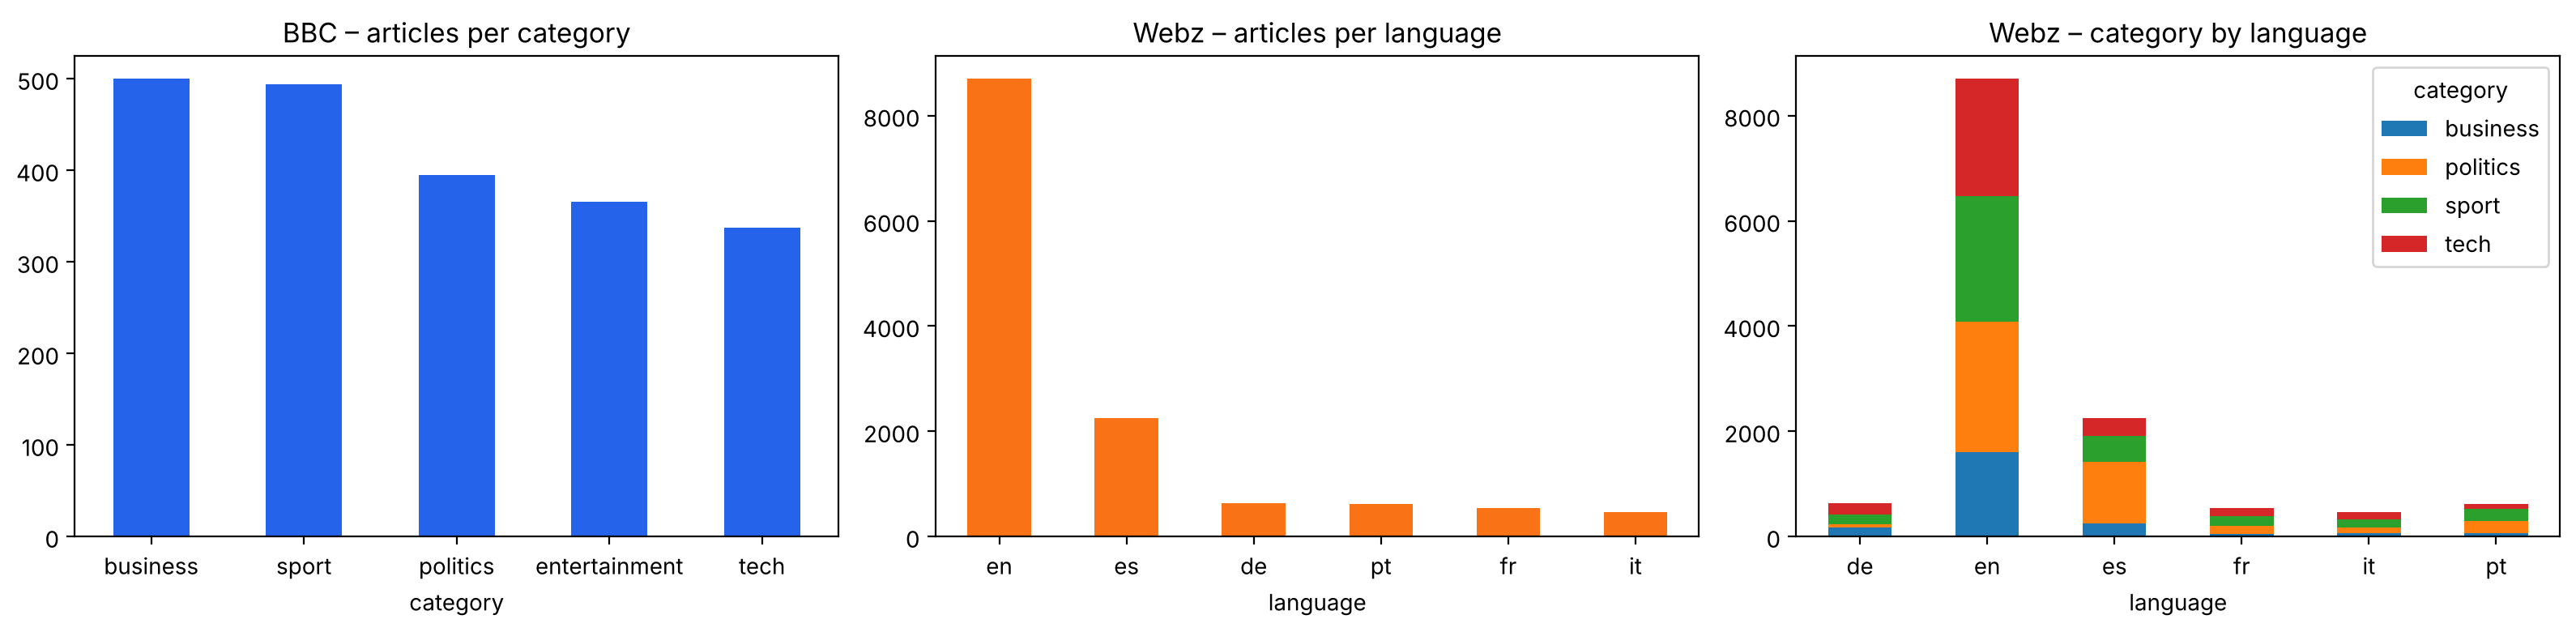

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
bbc["category"].value_counts().plot.bar(ax=axes[0], title="BBC – articles per category", color="#2563eb")
webz["language"].value_counts().plot.bar(ax=axes[1], title="Webz – articles per language", color="#f97316")
pd.crosstab(webz["language"], webz["category"]).plot.bar(stacked=True, ax=axes[2], title="Webz – category by language")
for ax in axes: ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

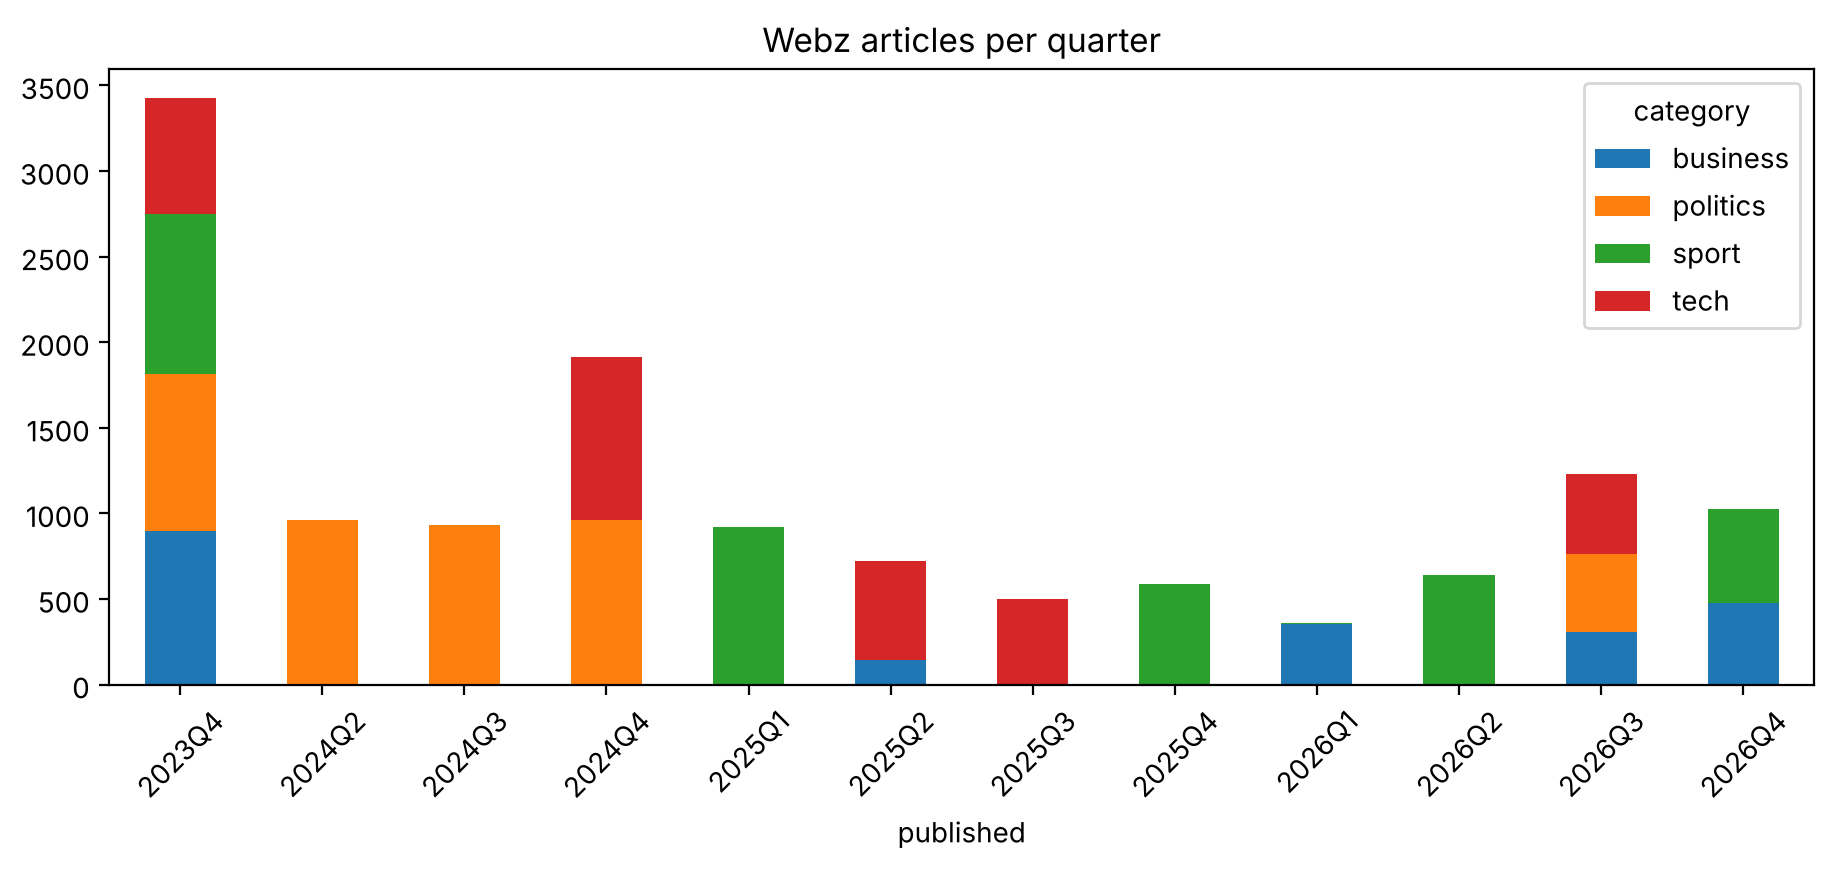

In [6]:
q = webz["published"].dt.tz_convert(None).dt.to_period("Q").astype(str)
pd.crosstab(q, webz["category"]).plot.bar(stacked=True, figsize=(11, 4), title="Webz articles per quarter")
plt.xticks(rotation=45); plt.show()

          BBC     Webz
count  2092.0  13213.0
mean    379.0    519.0
std     242.0    376.0
min      84.0     40.0
25%     239.0    268.0
50%     324.0    428.0
75%     466.0    662.0
max    4428.0   2633.0


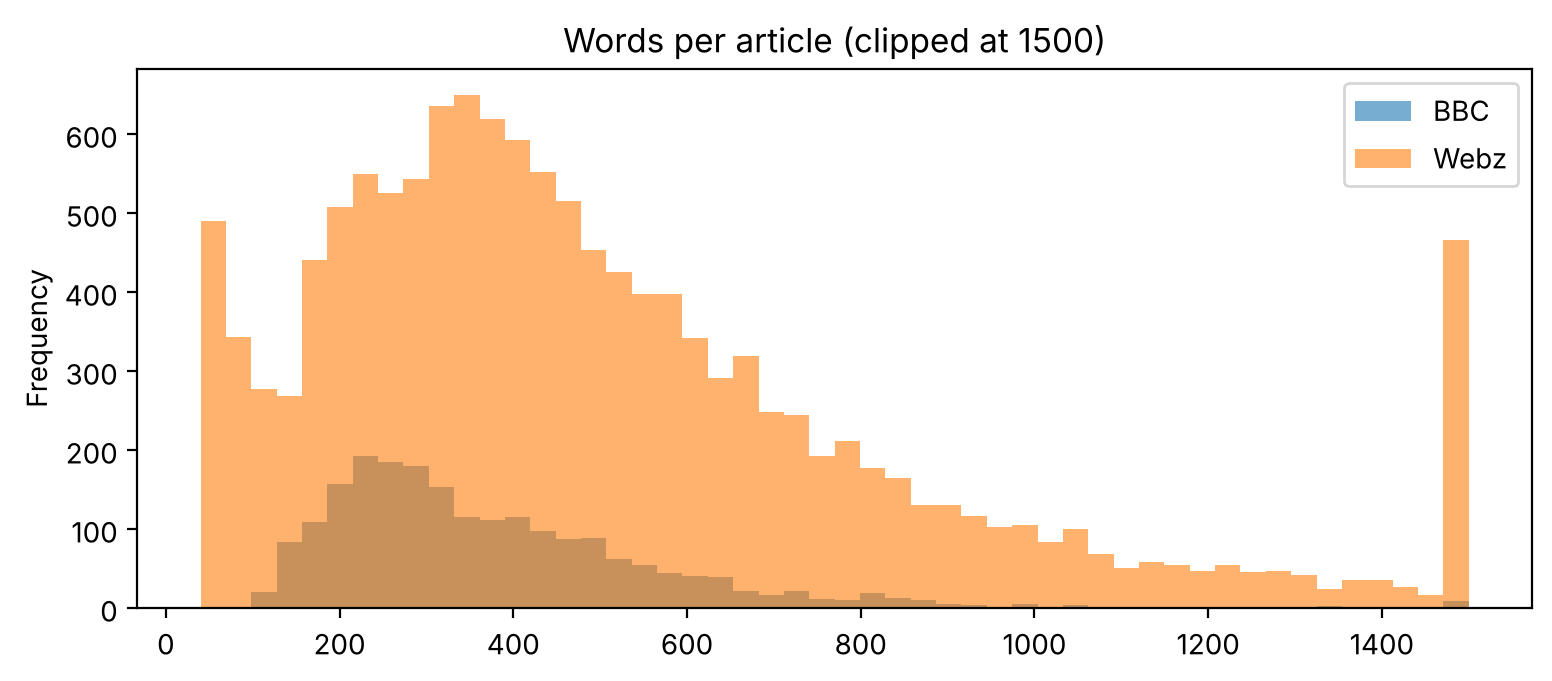

In [7]:
lengths = pd.DataFrame({"BBC": bbc["text"].str.split().str.len(), "Webz": webz["text"].str.split().str.len()})
print(lengths.describe().round(0))
lengths.clip(upper=1500).plot.hist(bins=50, alpha=0.6, figsize=(9, 3.5), title="Words per article (clipped at 1500)"); plt.show()

## 4. Preprocessing – two versions of every text
* `clean()` keeps casing and punctuation → used by spaCy, VADER, summarisation.
* `normalize()` lower-cases, repairs contractions, turns money into tokens and removes language-specific stop words → used by TF-IDF and topic models.

In [8]:
from src.data_processing.text_preprocessor import TextPreprocessor
pre = TextPreprocessor()
example = bbc.loc[0, "text"][:400]
print("CLEAN     :", pre.clean(example)[:300]); print()
print("NORMALIZED:", pre.normalize(example)[:300]); print()
es = webz[webz.language == "es"].iloc[0]["text"][:300]
print("SPANISH   :", TextPreprocessor(language="es").normalize(es)[:200])

CLEAN     : Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier. The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said four

NORMALIZED: quarterly profits media giant timewarner jumped percent_value currency_usd currency_gbp months december currency_usd earlier firm biggest investors google benefited sales high speed internet connections higher advert sales timewarner fourth quarter sales rose percent_value currency_usd currency_usd 

SPANISH   : laura vanessa rojas barragán autores laura vanessa rojas barragan cine colombia sorprende usuarios anunciar promoción cine currency_usd comida gratis cine colombia anunció próximo diciembre habrá serv


In [9]:
from src.data_processing.feature_extractor import describe_features
describe_features(bbc)

,log_chars,log_words,avg_word_len,digit_ratio,quote_ratio,question_ratio,upper_ratio
category,,,,,,,
business,7.4985,5.7053,5.0338,0.0164,0.0176,0.0001,0.0304
entertainment,7.4284,5.6668,4.8481,0.0113,0.0204,0.0004,0.0427
politics,7.7919,6.0166,4.9207,0.0061,0.0340,0.0004,0.0302
sport,7.3967,5.6505,4.7629,0.0086,0.0305,0.0003,0.0390
tech,7.9260,6.1495,4.9271,0.0074,0.0182,0.0006,0.0274


## 5. Language-label check
The Webz `language` field is produced automatically and is sometimes wrong (e.g. a Vietnamese page labelled German).
NewsBot's own language detector (notebook 05) double-checks every label during `NewsBot2.build()` and drops
articles where a confident detection disagrees.

In [10]:
from src.multilingual.language_detector import LanguageDetector
X, y = LanguageDetector.make_training_snippets(webz.groupby("language").sample(300, random_state=0)["text"],
                                               webz.groupby("language").sample(300, random_state=0)["language"])
det = LanguageDetector().train(X, y)
pred = det.detect_batch(webz["text"].str[:600])
mismatch = webz[np.array(pred) != webz["language"].values]
print(f"{len(mismatch)} of {len(webz)} Webz articles have a language label that disagrees with the detector")
mismatch[["title", "language"]].assign(detected=np.array(pred)[np.array(pred) != webz["language"].values]).head(8)

20:25:08 | INFO    | src.multilingual.language_detector | Language detector trained on 5353 samples ({'de': 896, 'en': 886, 'es': 891, 'fr': 891, 'it': 891, 'pt': 898})


31 of 13213 Webz articles have a language label that disagrees with the detector


,title,language,detected
1462,අපගේ අරමුණ ආයෝජකයන් සඳහා දිගු කාලීන හවුල්කාරීත්වයක් ගොඩනැගීමයි,en,pt
1615,O legado de José María Castellano (Inditex e Novagalicia): 130 millóns en activos e perdas no grupo familiar,es,pt
1679,"A aposta de Resonac pola economía verde na Coruña, pendente da posible venda tras recibir máis de cinco millóns de a...",es,pt
3988,"#324 La OTAN rechazó la propuesta de Vladimir Putin de alto el fuego: ""No es un plan de paz, es más agresión""",en,es
5115,സെബി അധ്യക്ഷ ഹാജരാകാത്തതിനെതിരേ കോൺഗ്രസ്,en,fr
5428,സൽമാൻഖാന് ഭീഷണിസന്ദേശം: യുവാവ് പിടിയിൽ,en,fr
6010,កិច្ចខិតខំប្រឹងប្រែងរបស់វៀតណាមក្នុងការការពារសិទ្ធិស្នូលរបស់កម្មករក្នុងបរិបទនៃការធ្វើសមាហរណកម្ម។,en,it
6088,ទីក្រុងដាណាំងបើកវគ្គបណ្តុះបណ្តាលលើកទី ២ ស្តីពីជំនាញការងារជួរមុខសម្រាប់ឆ្នាំ ២០២៦។,en,pt


## Key takeaways
* 2,092 unique BBC articles (133 exact duplicates removed) and ~13k Webz articles in en/es/de/pt/fr/it.
* Webz is English-heavy (≈65%) and politics/sport-heavy in Spanish – the multilingual analysis must normalise by language.
* Dates cluster in weekly snapshots, so trends are reported **per quarter**.
* BBC text now keeps its original casing → much better entity recognition (measured in notebook 02).